## Problem Statement

You are working for Accenture as a Data Scientist. Accenture has been commissioned by an insurance company to develop a tool to optimize their marketing efforts. They have given us a data set as a result of an email marketing campaign. The data set includes customer information, described below, as a well as whether the customer responded to the marketing campaign or not.

Design a model that will be able to predict whether a customer will respond to the marketing campaign based on his/her information. In other words, predict the responded target variable described above based on all the input variables provided.

Briefly answer the following questions:

    Describe your model and why did you choose this model over other types of models?
    Describe any other models you have tried and why do you think this model preforms better?
    How did you handle missing data?
    How did you handle categorical (string) data?
    How did you handle unbalanced data?
    How did you handle outliers?
    How did you test your model?


| Type | Variable Name | Description |
| --- | --- | --- |
| **Input Variable** | `custAge` | The age of the customer (in years) |
| **Input Variable** | `profession` | Type of job |
| **Input Variable** | `marital` | Marital status |
| **Input Variable** | `schooling` | Education level |
| **Input Variable** | `default` | Has a previous defaulted account? |
| **Input Variable** | `housing` | Has a housing loan? |
| **Input Variable** | `contact` | Preferred contact type |
| **Input Variable** | `month` | Last contact month |
| **Input Variable** | `day_of_week` | Last contact day of week |
| **Input Variable** | `campaign` | Number of times the customer was contacted during this campaign |
| **Input Variable** | `pdays` | Number of days that passed by after the client was last contacted from a previous campaign (numeric; `999` means client was not previously contacted) |
| **Input Variable** | `previous` | Number of contacts performed before this campaign for this client |
| **Input Variable** | `poutcome` | Outcome of the previous marketing campaign |
| **Input Variable** | `emp.var.rate` | Employment variation rate - quarterly indicator |
| **Input Variable** | `cons.price.idx` | Consumer price index - monthly indicator |
| **Input Variable** | `cons.conf.idx` | Consumer confidence index - monthly indicator |
| **Input Variable** | `euribor3m` | Euribor 3 months rate - daily indicator |
| **Input Variable** | `nr.employed` | Number of employees - quarterly indicator |
| **Input Variable** | `pmonths` | Number of months that passed by after the client was last contacted from a previous campaign (numeric; `999` means client was not previously contacted) |
| **Input Variable** | `pastEmail` | Number of previous emails sent to this user |
| **Target Variable** | `responded` | Did the customer respond to the marketing campaign and purchase a policy? |

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

## 1. Import data


In [2]:
!pip install openpyxl


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
train_df = pd.read_excel('../data/train.xlsx')


In [3]:
train_df.head()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded,profit,id
0,34.0,admin.,single,university.degree,no,no,yes,cellular,apr,wed,...,-1.8,93.075,-47.1,1.498,5099.1,999.0,0.0,no,NaN,1.0
1,31.0,services,single,high.school,no,no,no,cellular,jul,thu,...,1.4,93.918,-42.7,4.968,5228.1,999.0,0.0,no,NaN,2.0
2,NaN,admin.,single,high.school,no,no,no,telephone,jun,NaN,...,1.4,94.465,-41.8,4.961,5228.1,999.0,0.0,no,NaN,3.0
3,52.0,admin.,divorced,university.degree,unknown,yes,no,cellular,jul,tue,...,1.4,93.918,-42.7,4.962,5228.1,999.0,0.0,no,NaN,4.0
4,39.0,blue-collar,single,NaN,unknown,yes,no,cellular,jul,tue,...,1.4,93.918,-42.7,4.961,5228.1,999.0,0.0,no,NaN,5.0


In [4]:
train_df.tail()


,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded,profit,id
8235,32.0,self-employed,single,university.degree,no,no,no,cellular,apr,thu,...,-1.8,93.075,-47.1,1.435,5099.1,999.0,0.0,yes,208.000000,8236.0
8236,NaN,housemaid,married,university.degree,no,no,no,cellular,jun,tue,...,-2.9,92.963,-40.8,1.099,5076.2,999.0,0.0,yes,129.000000,8237.0
8237,85.0,housemaid,married,NaN,unknown,yes,no,cellular,apr,tue,...,-1.8,93.749,-34.6,0.642,5008.7,999.0,1.0,yes,33.000000,8238.0
8238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,172.112069,NaN
8239,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-87622.112070,NaN


Since the problem staement is a classification problem.'Responded' is our target variable. We will drop 'profit' from training data.
We will remove the indentifier columns to prevent data leakage too.

In [5]:
train_df.drop(columns=['profit','id'], inplace=True)

In [6]:
train_df.drop(train_df.tail(2).index, inplace=True)

In [7]:
# Clean target labels before splitting
train_df["responded"] = (
    train_df["responded"]
    .astype("string")
    .str.strip()
    .str.lower()
)
train_df = train_df.dropna(subset=["responded"]).copy()
train_df = train_df[train_df["responded"].isin(["yes", "no"])].copy()

# Remove exact duplicate rows before splitting to prevent overlap
# between development and demo holdout data.
duplicates_removed = int(train_df.duplicated().sum())
train_df = train_df.drop_duplicates().reset_index(drop=True)

# Reserve 10% for the final demo holdout before EDA/model decisions
development_df, demo_holdout_df = train_test_split(
    train_df,
    test_size=0.10,
    stratify=train_df["responded"],
    random_state=42
)

# Existing notebook workflow uses train_df for EDA/model development
train_df = development_df.reset_index(drop=True).copy()
demo_holdout_df = demo_holdout_df.reset_index(drop=True).copy()

print("Exact duplicates removed before splitting:", duplicates_removed)
print(f"Development data (90%): {len(train_df):,} rows")
print(f"Demo holdout (10%): {len(demo_holdout_df):,} rows")


Exact duplicates removed before splitting: 36
Development data (90%): 7,381 rows
Demo holdout (10%): 821 rows


In [8]:
train_df.columns

Index(['custAge', 'profession', 'marital', 'schooling', 'default', 'housing',
       'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'pmonths', 'pastEmail',
       'responded'],
      dtype='object')

In [10]:
print("Number of Development rows:", train_df.shape[0])
print("Number of Development columns:", train_df.shape[1])
print("Number of Demo Holdout rows:", demo_holdout_df.shape[0])
print("Number of Demo Holdout columns:", demo_holdout_df.shape[1])


Number of Development rows: 7381
Number of Development columns: 22
Number of Demo Holdout rows: 821
Number of Demo Holdout columns: 22


In [11]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7381 entries, 0 to 7380
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   custAge         5574 non-null   float64
 1   profession      7381 non-null   object 
 2   marital         7381 non-null   object 
 3   schooling       5227 non-null   object 
 4   default         7381 non-null   object 
 5   housing         7381 non-null   object 
 6   loan            7381 non-null   object 
 7   contact         7381 non-null   object 
 8   month           7381 non-null   object 
 9   day_of_week     6668 non-null   object 
 10  campaign        7381 non-null   float64
 11  pdays           7381 non-null   float64
 12  previous        7381 non-null   float64
 13  poutcome        7381 non-null   object 
 14  emp.var.rate    7381 non-null   float64
 15  cons.price.idx  7381 non-null   float64
 16  cons.conf.idx   7381 non-null   float64
 17  euribor3m       7381 non-null   f

In [12]:
train_df.describe()

,custAge,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail
count,5574.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000,7381.000000
mean,40.059203,2.530416,960.529197,0.186018,0.048449,93.569603,-40.563081,3.578880,5165.136282,960.298564,0.366346
std,10.615953,2.732977,191.627311,0.520787,1.569746,0.579289,4.661979,1.746065,72.970589,192.774546,1.305367
min,18.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000,0.000000
25%,32.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000,999.000000,0.000000
50%,38.000000,2.000000,999.000000,0.000000,1.100000,93.444000,-41.800000,4.857000,5191.000000,999.000000,0.000000
75%,47.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,999.000000,0.000000
max,94.000000,40.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,999.000000,25.000000


In [13]:
train_df.isna().sum()

custAge           1807
profession           0
marital              0
schooling         2154
default              0
housing              0
loan                 0
contact              0
month                0
day_of_week        713
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
pmonths              0
pastEmail            0
responded            0
dtype: int64

## 2.EDA

#### 2.1 Target analysis

In [14]:
target =train_df['responded']

In [15]:
target.value_counts()

responded
no     6546
yes     835
Name: count, dtype: Int64

In [16]:
target.value_counts(normalize=True)

responded
no     0.886872
yes    0.113128
Name: proportion, dtype: Float64

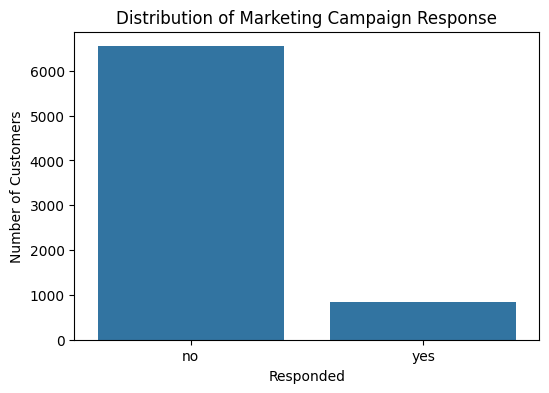

In [17]:
plt.figure(figsize =(6,4))
sns.countplot(
    data = train_df.drop(columns = 'responded'),
    x = train_df['responded']
)

plt.title("Distribution of Marketing Campaign Response")
plt.xlabel("Responded")
plt.ylabel("Number of Customers")

plt.show()

*The is class imbalance present in the target variable*. Out of all the people reached, only 11.26~ percent people responded. 
This might motivate us to use a ensemble learning method since they handle unbalance data.

### 2.2 train datatype summary

In [18]:
dtype_train_summary = pd.DataFrame({
    "dtype": train_df.dtypes,
    "missing": train_df.isna().sum(),
    "unique_values": train_df.nunique()
})

dtype_train_summary

,dtype,missing,unique_values
custAge,float64,1807,72
profession,object,0,12
marital,object,0,4
schooling,object,2154,8
default,object,0,3
housing,object,0,3
loan,object,0,3
contact,object,0,2
month,object,0,10
day_of_week,object,713,5


### 2.3 duplicate analysis

In [20]:
print("Exact duplicate rows removed before split:", duplicates_removed)
print("Duplicate rows remaining in development data:", int(train_df.duplicated().sum()))


Exact duplicate rows removed before split: 36
Duplicate rows remaining in development data: 0


In [21]:
train_df[train_df.duplicated(keep=False)]

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded


Observation:

Exact duplicate rows are removed before the split so duplicate records cannot appear in both development and demo holdout data.


### 2.4 Missing Value analysis

In [22]:
null_columns = ['schooling','custAge','day_of_week']

In [28]:
missing_summary = (
    train_df.isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(train_df) * 100
)

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

missing_summary

,missing_count,missing_percent
schooling,2406,29.206118
custAge,2014,24.447681
day_of_week,787,9.553290
previous,0,0.000000
pastEmail,0,0.000000
pmonths,0,0.000000
nr.employed,0,0.000000
euribor3m,0,0.000000
cons.conf.idx,0,0.000000
cons.price.idx,0,0.000000


- 'Missing values': custAge, schooling and days_of_week contain missing values in both test and train.

Cannot drop the null rows due to their large number.
Nulls a are represented as Nan. Ensemble models handle missing values natively. BUt we can use a custom function for baseline algorithms. The custo function will implement forard fill.

### 2.5 Categorical And Numerical analysis

In [23]:
categorical_data = train_df.select_dtypes(exclude=['number'])
numerical_data = train_df.select_dtypes(include=['number'])

categorical_data.drop(columns='responded', inplace=True)

### 2.5.1 Categorical Bivariate analysis

In [24]:
categorical_features = categorical_data.columns.tolist()

for col in categorical_features:
    temp = train_df.copy()
    temp[col] = temp[col].fillna("Missing")

    response_rate = (
        pd.crosstab(
            temp[col],
            temp["responded"],
            normalize="index"
        )["yes"] * 100
    ).sort_values(ascending=False)

    print(f"\n--- {col} ---")
    print(response_rate.round(2))


--- profession ---
profession
student          34.78
retired          23.76
unemployed       14.77
admin.           13.07
self-employed    12.75
unknown          11.29
management       11.11
technician        9.74
entrepreneur      9.41
housemaid         8.12
services          7.99
blue-collar       7.88
Name: yes, dtype: float64

--- marital ---
marital
single      13.74
unknown     12.50
married     10.50
divorced     9.54
Name: yes, dtype: float64

--- schooling ---
schooling
unknown                17.33
university.degree      13.21
Missing                11.42
high.school            11.25
professional.course    11.08
basic.6y                9.19
basic.4y                8.99
basic.9y                8.26
illiterate              0.00
Name: yes, dtype: float64

--- default ---
default
no         12.81
unknown     5.26
yes         0.00
Name: yes, dtype: float64

--- housing ---
housing
unknown    12.35
yes        11.76
no         10.75
Name: yes, dtype: float64

--- loan ---
loan
unkno

In [25]:
selected_cat = [
    "profession",
    "schooling",
    "contact",
    "month",
    "poutcome"
]

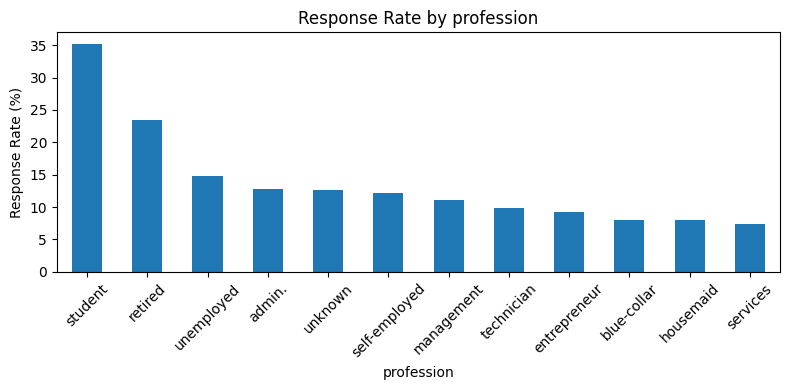

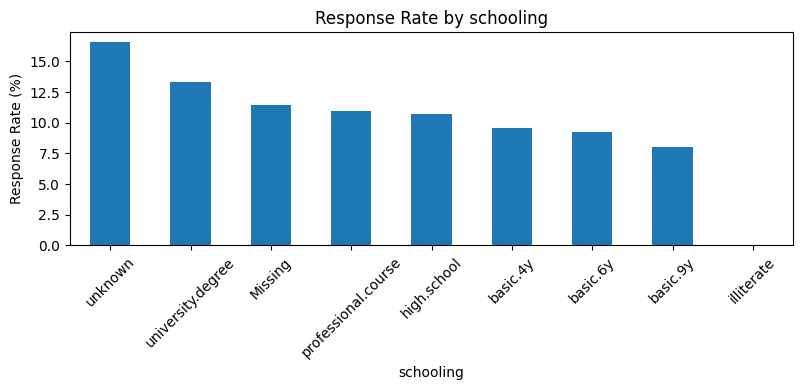

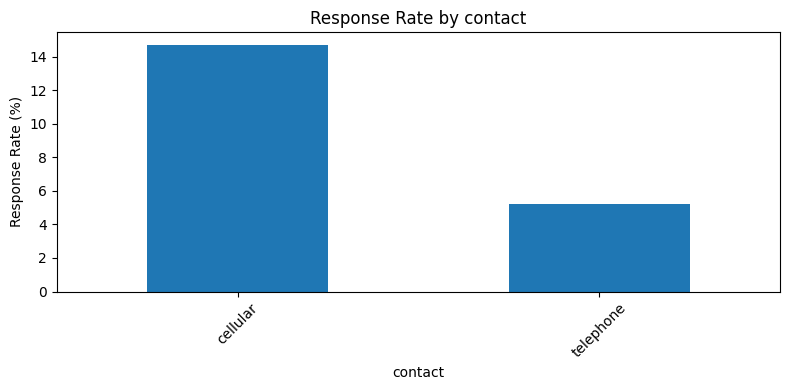

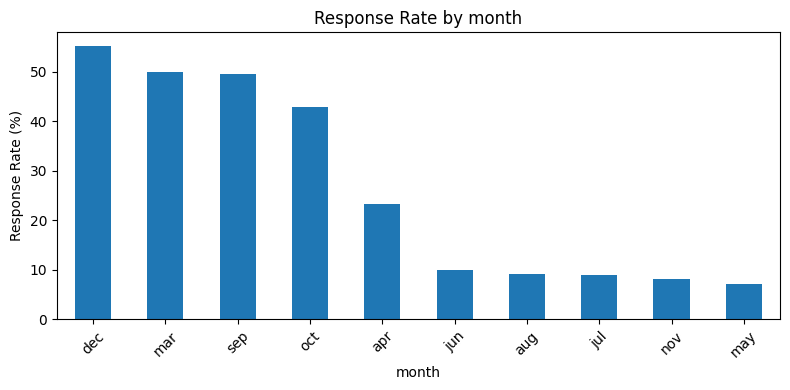

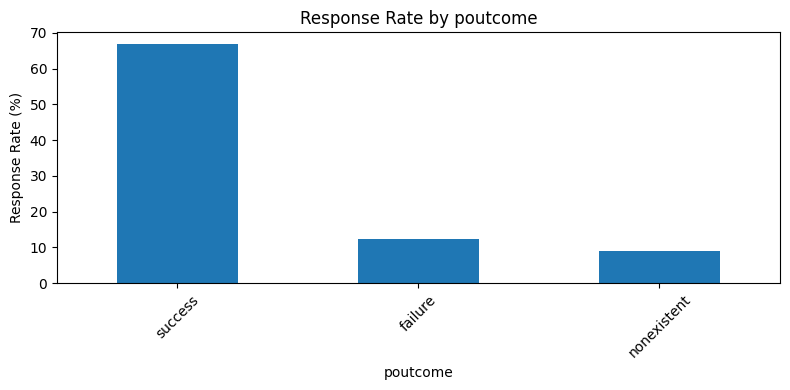

In [32]:
for col in selected_cat:
    temp = train_df.copy()
    temp[col] = temp[col].fillna("Missing")

    response_rate = (
        pd.crosstab(
            temp[col],
            temp["responded"],
            normalize="index"
        )["yes"] * 100
    ).sort_values(ascending=False)

    plt.figure(figsize=(8, 4))
    response_rate.plot(kind="bar")
    plt.title(f"Response Rate by {col}")
    plt.ylabel("Response Rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 2.5.2 Numerical Bivariate analysis

In [26]:
train_df.groupby("responded")[numerical_data.columns].mean().T

responded,no,yes
custAge,39.953179,40.907916
campaign,2.588145,2.077844
pdays,983.525053,780.252695
previous,0.144974,0.507784
emp.var.rate,0.218607,-1.285509
cons.price.idx,93.598074,93.346410
cons.conf.idx,-40.645249,-39.918922
euribor3m,3.773895,2.050054
nr.employed,5174.428720,5092.288024
pmonths,983.436597,778.907465


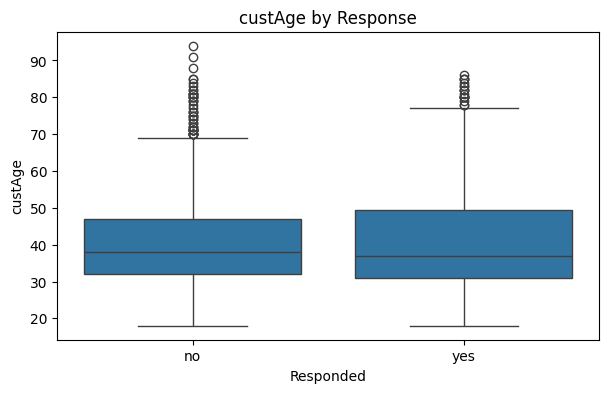

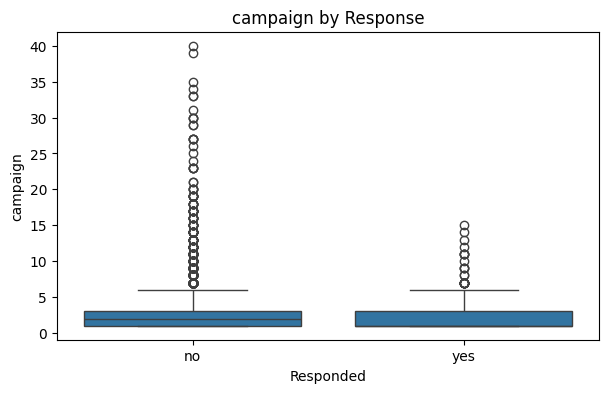

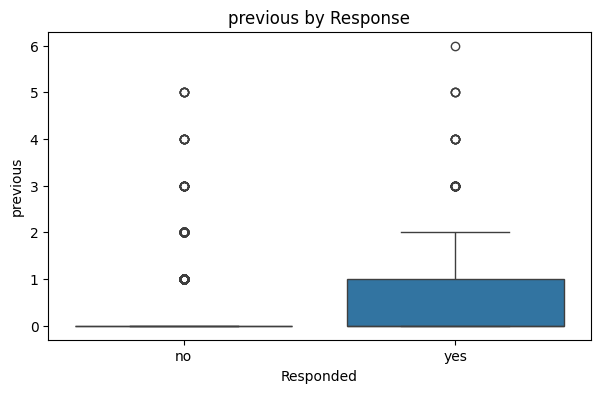

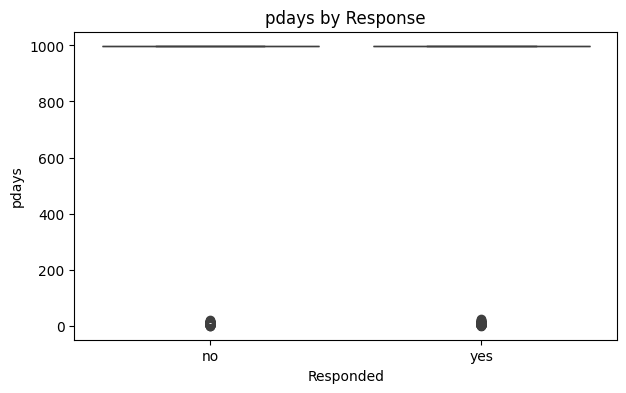

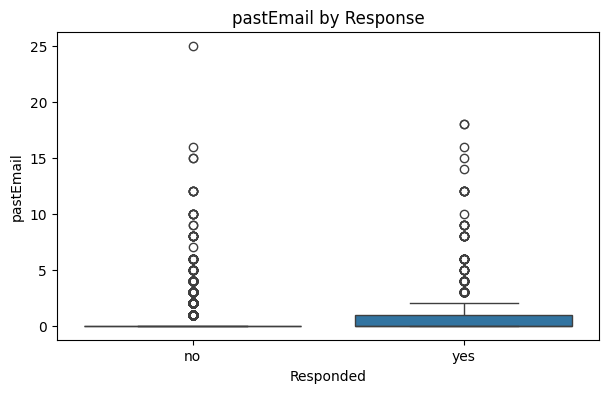

In [27]:
selected_num = [
    "custAge",
    "campaign",
    "previous",
    "pdays",
    "pastEmail"
]

for col in selected_num:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=train_df,
        x="responded",
        y=col
    )

    plt.title(f"{col} by Response")
    plt.xlabel("Responded")
    plt.ylabel(col)

    plt.show()

### 2.6 Outlier Detection 

In [28]:
#Check Skewnes
skewness = numerical_data.skew().sort_values(ascending=False)

skewness

pastEmail         6.199124
campaign          4.939277
previous          3.850303
custAge           0.866716
cons.conf.idx     0.307192
cons.price.idx   -0.189911
euribor3m        -0.653833
emp.var.rate     -0.669413
nr.employed      -1.012961
pmonths          -4.780930
pdays            -4.781056
dtype: float64

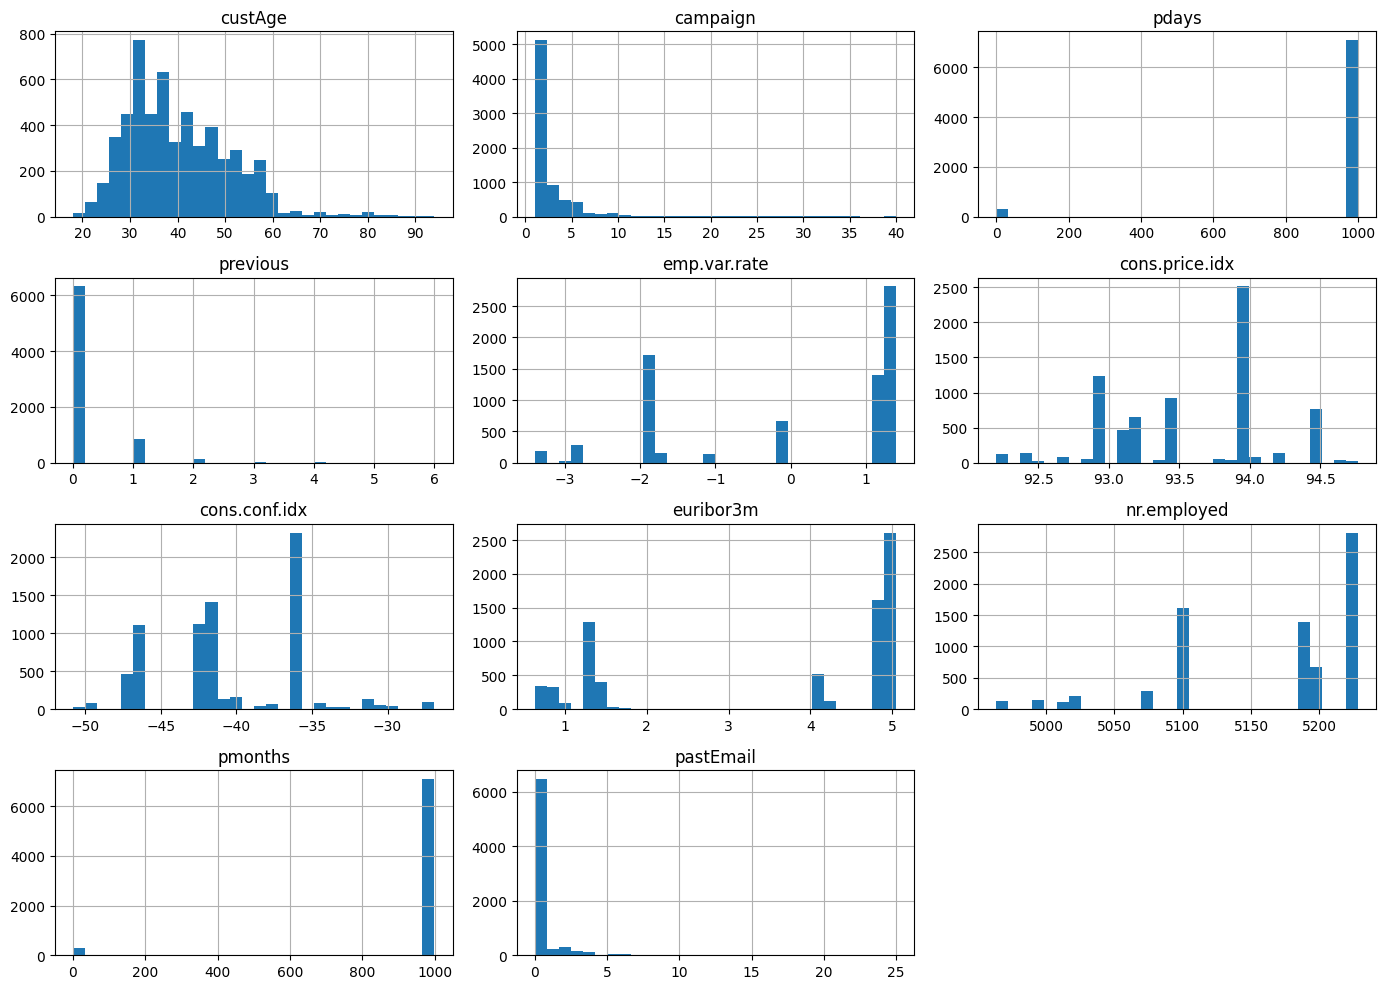

In [29]:
numerical_data.hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

Since there is high skeness in the the data we would use IQR instead of Z-score method to deal with outliers

In [30]:
train_df['pdays'].value_counts()

pdays
999.0    7095
6.0        83
3.0        78
4.0        22
9.0        16
7.0        14
2.0        13
12.0       10
10.0        8
14.0        6
13.0        5
5.0         5
11.0        4
16.0        4
15.0        4
1.0         3
8.0         3
0.0         3
25.0        1
17.0        1
21.0        1
19.0        1
22.0        1
Name: count, dtype: int64

In [31]:
train_df['pmonths'].value_counts()

pmonths
999.000000    7095
0.200000        83
0.100000        78
0.133333        22
0.300000        16
0.233333        14
0.066667        13
0.400000        10
0.333333         8
0.466667         6
0.433333         5
0.166667         5
0.366667         4
0.533333         4
0.500000         4
0.033333         3
0.266667         3
0.000000         3
0.833333         1
0.566667         1
0.700000         1
0.633333         1
0.733333         1
Name: count, dtype: int64

We have to check skew without 999, which is used to indicate users who have not been reached.

In [32]:
skew_without_999 = numerical_data.copy()

skew_without_999["pdays"] = skew_without_999["pdays"].replace(999, np.nan)
skew_without_999["pmonths"] = skew_without_999["pmonths"].replace(999, np.nan)

skew_without_999.skew().sort_values(ascending=False)

pastEmail         6.199124
campaign          4.939277
previous          3.850303
pdays             1.559470
pmonths           1.559470
custAge           0.866716
cons.conf.idx     0.307192
cons.price.idx   -0.189911
euribor3m        -0.653833
emp.var.rate     -0.669413
nr.employed      -1.012961
dtype: float64

| Skewness | Interpretation |
|---:|---|
| -0.5 to 0.5 | Approximately symmetric |
| 0.5 to 1 | Moderately skewed |
| > 1 | Highly right-skewed |
| -1 to -0.5 | Moderately left-skewed |
| < -1 | Highly left-skewed |

Skewnes of pdays and pmonths goes from Highlt left skewed to Highly right skews 

In [35]:
outlier_summary = []

for col in numerical_data.columns:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "IQR" : IQR,
        "outlier_count": outlier_count,
        "outlier_percent": outlier_count / len(train_df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "outlier_percent",
    ascending=False
)

,feature,IQR,outlier_count,outlier_percent
3,previous,0.000,1068,14.469584
10,pastEmail,0.000,919,12.450887
1,campaign,2.000,411,5.568351
2,pdays,0.000,286,3.874814
9,pmonths,0.000,286,3.874814
6,cons.conf.idx,6.300,91,1.232895
0,custAge,15.000,81,1.097412
4,emp.var.rate,3.200,0,0.000000
5,cons.price.idx,0.919,0,0.000000
7,euribor3m,3.627,0,0.000000


In [37]:
print("pdays = 999:")
print(train_df["pdays"].value_counts().head())

print("\npmonths = 999:")
print(train_df["pmonths"].value_counts().head())

pdays = 999:
pdays
999.0    7095
6.0        83
3.0        78
4.0        22
9.0        16
Name: count, dtype: int64

pmonths = 999:
pmonths
999.000000    7095
0.200000        83
0.100000        78
0.133333        22
0.300000        16
Name: count, dtype: int64


## 3. Modelling Split
The cleaned labelled dataset is split before EDA into:

- 90% development data for EDA, model comparison, hyperparameter tuning and final training.
- 10% demo holdout reserved for final evaluation.

Within the development data, a stratified 80:20 split is used for model training and validation. After selecting the model, it is retrained on the entire 90% development dataset and evaluated on the untouched 10% demo holdout.

In [38]:
X = train_df.drop(columns ='responded')
y = train_df['responded'].map({"yes":1, "no":0})

In [39]:
X_train, X_val,y_train, y_val = train_test_split(X,y,test_size= 0.2, stratify = y, random_state = 42) 

## 4. Feature Engineering

In [40]:
def engineer_features(df):
    df = df.copy()

    # Previous contact indicator
    df["previously_contacted"] = (df["pdays"] != 999).astype(int)

    # Convert sentinel values to missing
    df["pdays"] = df["pdays"].replace(999, np.nan)
    df["pmonths"] = df["pmonths"].replace(999, np.nan)

    return df

In [41]:
X_train = engineer_features(X_train)
X_val = engineer_features(X_val)

## 5. Model Specific Preprocessing 

| | Logistic Regression | Random Forest | LightGBM |
|-|-|-|-|
| Imputation | Yes | Yes | Native missing handling |
| One-hot encoding | Yes | Yes | No |
| Scaling | Yes | No | No |
| Native categorical | No | No | **Yes** |

In [42]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print("Numerical:", numeric_cols)
print("Categorical:", categorical_cols)

Numerical: ['custAge', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pmonths', 'pastEmail', 'previously_contacted']
Categorical: ['profession', 'marital', 'schooling', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 5.1 Logistic regression

Logistic Regression expects numerical inputs, so we need to:
1. Impute missing numerical values
2. Impute missing categorical values
3. One-hot encode categorical variables
4. Scale numerical variables

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


In [44]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
    ])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown='ignore'))
])

lr_preprocessor = ColumnTransformer([
    ("num",numeric_transformer, numeric_cols),
    ("cat", categorical_transformer,categorical_cols)
])

lr_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression( class_weight="balanced"))
])

In [45]:
lr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['custAge', 'campaign',
                                                   'pdays', 'previous',
                                                   'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed', 'pmonths',
                                                   'pastEmail',
                                                   'previously_contacted']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['profession', 'marital',
                                                   'schooling', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

### 5.2 Random Forest
1. Impute missing categorical values
2. Impute missing numerical values
3. One-hot encode categorical values

In [46]:
rf_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

rf_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

rf_preprocessor = ColumnTransformer([
    ("num",rf_numeric_transformer, numeric_cols),
    ("cat",rf_categorical_transformer,categorical_cols)
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier",RandomForestClassifier(n_estimators=500,
        random_state=42,
        n_jobs=-1, class_weight="balanced"))
])

In [47]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['custAge', 'campaign',
                                                   'pdays', 'previous',
                                                   'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed', 'pmonths',
                                                   'pastEmail',
                                                   'previously_contacted']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['profession', 'marital',
                                                   'schooling', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])

### 5.3 LightGBM
LightGBM can work with:
- missing numerical values
- categorical variables
- nonlinear relationships
So we don't need the same preprocessing pipeline.
We're going to let LightGBM use its native categorical handling.

In [48]:
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()

for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_val_lgb[col] = X_val_lgb[col].astype("category")

for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].cat.add_categories(["Missing"])
    X_val_lgb[col] = X_val_lgb[col].cat.add_categories(["Missing"])

    X_train_lgb[col] = X_train_lgb[col].fillna("Missing")
    X_val_lgb[col] = X_val_lgb[col].fillna("Missing")

In [49]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=30,
    random_state=42,
    verbosity=-1,
    is_unbalance = True
)

In [50]:
lgb_model.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_cols
)

LGBMClassifier(is_unbalance=True, learning_rate=0.05, n_estimators=300,
               num_leaves=30, random_state=42, verbosity=-1)

## 6. Model evaluation

In [51]:

def evaluate_model(name, model, X_valid, y_valid):

    # Generate class predictions and response probabilities
    y_pred = model.predict(X_valid)
    y_prob = model.predict_proba(X_valid)[:, 1]

    # Calculate metrics
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_valid, y_prob),
        "Average Precision": average_precision_score(
            y_valid, y_prob
        )
    }

    # Display classification report
    print(f"\n{'=' * 50}")
    print(f"{name} — Evaluation")
    print("=" * 50)

    print("\nClassification Report:")
    print(classification_report(
        y_valid,
        y_pred,
        labels=[0, 1],
        target_names=["No Response", "Responded"],
        zero_division=0
    ))

    # Calculate confusion matrix in a fixed label order
    cm = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    )

    # Visualise the confusion matrix
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Response", "Responded"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

    return metrics



Logistic Regression — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.95      0.83      0.89      1310
   Responded       0.33      0.66      0.44       167

    accuracy                           0.81      1477
   macro avg       0.64      0.75      0.66      1477
weighted avg       0.88      0.81      0.84      1477



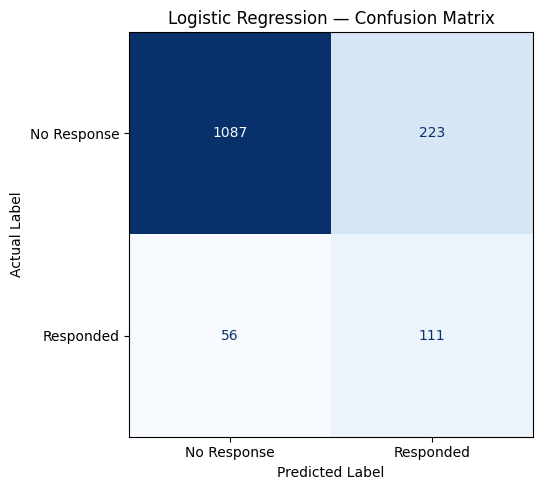

In [52]:
lr_metrics = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_val,
    y_val
)



Random Forest — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.91      0.97      0.94      1310
   Responded       0.50      0.22      0.30       167

    accuracy                           0.89      1477
   macro avg       0.70      0.59      0.62      1477
weighted avg       0.86      0.89      0.87      1477



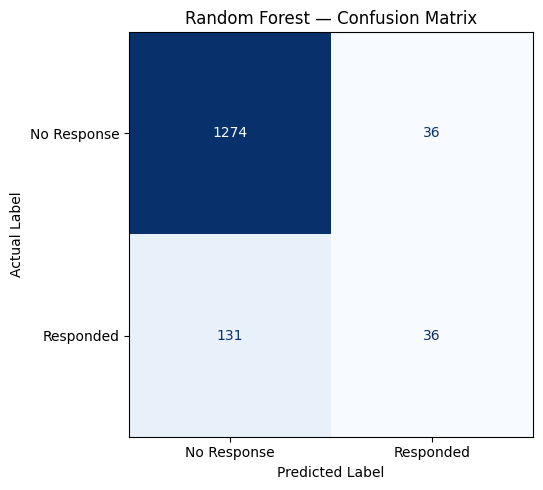

In [53]:

rf_metrics = evaluate_model(
    "Random Forest",
    rf_model,
    X_val,
    y_val
)



LightGBM — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.93      0.90      0.91      1310
   Responded       0.37      0.47      0.42       167

    accuracy                           0.85      1477
   macro avg       0.65      0.69      0.67      1477
weighted avg       0.87      0.85      0.86      1477



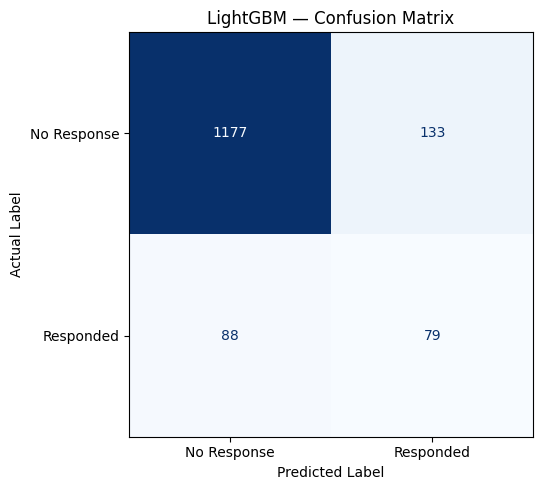

In [54]:

lgb_metrics = evaluate_model("LightGBM",lgb_model,X_val_lgb,y_val)

## 7. Model Comparison

In [57]:
results = pd.DataFrame([
    lr_metrics,
    rf_metrics,
    lgb_metrics
])

results = results.set_index("Model")

results.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Logistic Regression,0.8111,0.3323,0.6647,0.4431,0.7958,0.4381
Random Forest,0.8869,0.5000,0.2156,0.3013,0.7647,0.3940
LightGBM,0.8504,0.3726,0.4731,0.4169,0.7577,0.3994


In [58]:
# rank models by metrics
metrics_to_compare = ['Accuracy',	'Precision'	,'Recall'	,'F1-score','ROC-AUC',	'Average Precision']

In [59]:
rankings = results[metrics_to_compare].rank(
    ascending = False,
    method = "min"
)

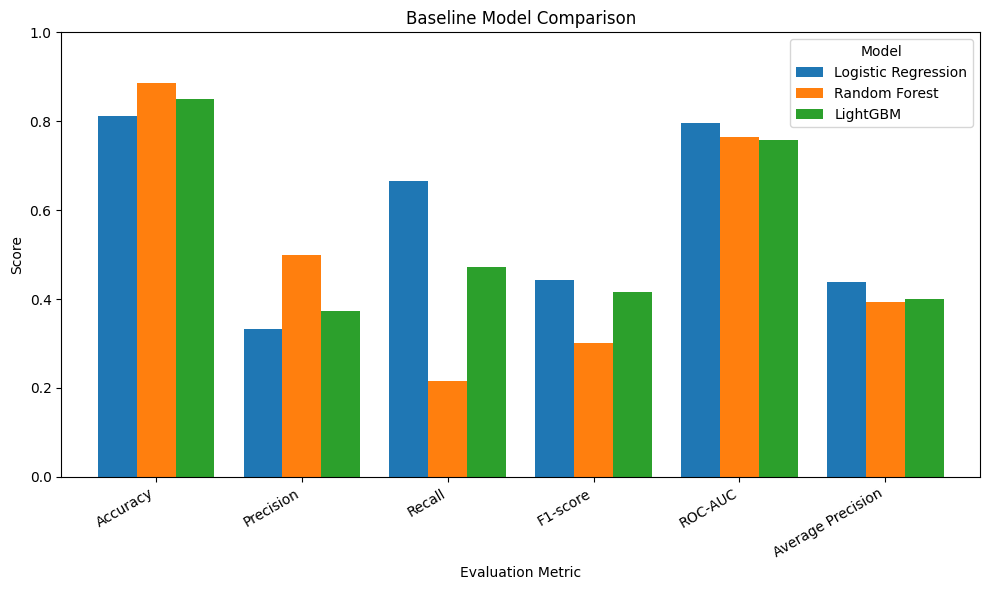

In [60]:
results[metrics_to_compare].T.plot(
    kind ="bar", figsize = (10,6), width = 0.8
)

plt.title("Baseline Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## 8. Hyper parameters tuning
We will test class balancing on our two stronges candidiates:
1. Logisitic Regression
2. LightGBM

In [61]:
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.base import clone
from scipy.stats import randint, loguniform, uniform
import lightgbm as lgb

In [62]:
# Shared CV folds for a fair comparison
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Parameter grid
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"]
}

# Balanced Logistic Regression pipeline
lr_search_model = clone(lr_model).set_params(
    classifier__class_weight="balanced"
)

# Grid search initialisation
lr_grid = GridSearchCV(
    estimator=lr_search_model,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [63]:
# Parameter distributions
lgb_param_distributions = {
    "n_estimators": randint(200, 701),
    "learning_rate": loguniform(0.01, 0.15),
    "num_leaves": randint(15, 64),
    "max_depth": [-1, 6, 8, 10, 12],
    "min_child_samples": randint(10, 81),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_alpha": loguniform(0.0001, 10),
    "reg_lambda": loguniform(0.0001, 10)
}

# Balanced LightGBM
lgb_search_model = lgb.LGBMClassifier(
    is_unbalance=True,
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

# Randomized search initialisation
lgb_random_search = RandomizedSearchCV(
    estimator=lgb_search_model,
    param_distributions=lgb_param_distributions,
    n_iter=60,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [64]:
# Fit Logistic Regression using GridSearchCV
lr_grid.fit(X_train, y_train)

print("Logistic Regression — Best Parameters:")
print(lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Logistic Regression — Best Parameters:
{'classifier__C': 1, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best CV F1-score: 0.4362


In [65]:

# Fit LightGBM using RandomizedSearchCV
lgb_random_search.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_cols
)

print("\nLightGBM — Best Parameters:")
print(lgb_random_search.best_params_)
print("Best CV F1-score:", round(lgb_random_search.best_score_, 4))

Fitting 3 folds for each of 60 candidates, totalling 180 fits

LightGBM — Best Parameters:
{'colsample_bytree': 0.7599443886861021, 'learning_rate': 0.011347052875275399, 'max_depth': 10, 'min_child_samples': 24, 'n_estimators': 389, 'num_leaves': 61, 'reg_alpha': 0.12357483710912165, 'reg_lambda': 0.008171653749019032}
Best CV F1-score: 0.4631


In [67]:

# Random Forest hyperparameter distributions
rf_param_distributions = {
    "classifier__n_estimators": randint(300, 801),
    "classifier__max_depth": [None, 10, 15, 20, 30, 40],
    "classifier__min_samples_split": randint(2, 21),
    "classifier__min_samples_leaf": randint(1, 11),
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "classifier__bootstrap": [True, False]
}

# Start with the existing Random Forest pipeline.
# Keep class balancing enabled and prevent nested parallelism.
rf_search_model = clone(rf_model).set_params(
    classifier__class_weight="balanced",
    classifier__n_jobs=1
)

# Randomized search
rf_random_search = RandomizedSearchCV(
    estimator=rf_search_model,
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)


In [68]:

# Fit Random Forest using RandomizedSearchCV
rf_random_search.fit(X_train, y_train)

print("Random Forest — Best Parameters:")
print(rf_random_search.best_params_)

print(
    "Best CV F1-score:",
    round(rf_random_search.best_score_, 4)
)


Fitting 3 folds for each of 30 candidates, totalling 90 fits
Random Forest — Best Parameters:
{'classifier__bootstrap': True, 'classifier__max_depth': 40, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 7, 'classifier__n_estimators': 583}
Best CV F1-score: 0.4969



Tuned Logistic Regression — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.95      0.83      0.89      1310
   Responded       0.33      0.66      0.44       167

    accuracy                           0.81      1477
   macro avg       0.64      0.75      0.66      1477
weighted avg       0.88      0.81      0.84      1477



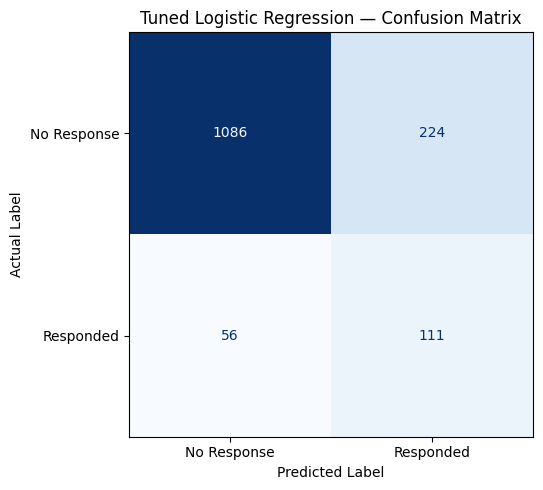


Tuned Random Forest — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.94      0.91      0.92      1310
   Responded       0.42      0.53      0.47       167

    accuracy                           0.87      1477
   macro avg       0.68      0.72      0.70      1477
weighted avg       0.88      0.87      0.87      1477



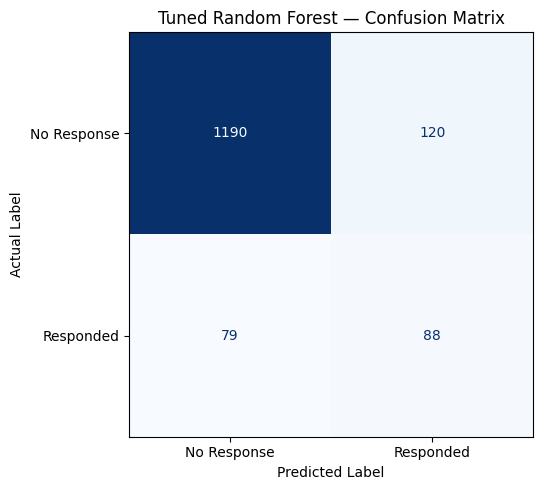


Tuned LightGBM — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.94      0.89      0.91      1310
   Responded       0.39      0.56      0.46       167

    accuracy                           0.85      1477
   macro avg       0.66      0.72      0.68      1477
weighted avg       0.88      0.85      0.86      1477



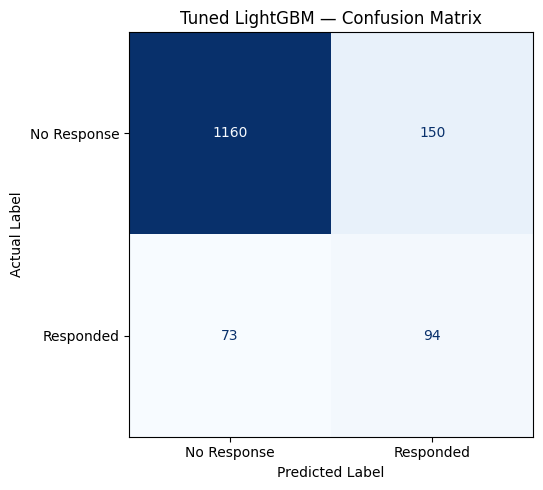

In [69]:

# Tuned Logistic Regression
lr_tuned_metrics = evaluate_model(
    "Tuned Logistic Regression",
    lr_grid.best_estimator_,
    X_val,
    y_val
)

# Tuned Random Forest
rf_tuned_metrics = evaluate_model(
    "Tuned Random Forest",
    rf_random_search.best_estimator_,
    X_val,
    y_val
)

# Tuned LightGBM
lgb_tuned_metrics = evaluate_model(
    "Tuned LightGBM",
    lgb_random_search.best_estimator_,
    X_val_lgb,
    y_val
)


In [70]:

tuned_comparison = pd.DataFrame([
    lr_tuned_metrics,
    rf_tuned_metrics,
    lgb_tuned_metrics
]).set_index("Model")

display(tuned_comparison.round(4))


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Tuned Logistic Regression,0.8104,0.3313,0.6647,0.4422,0.7955,0.4377
Tuned Random Forest,0.8653,0.4231,0.5269,0.4693,0.7794,0.4256
Tuned LightGBM,0.8490,0.3852,0.5629,0.4574,0.7756,0.4329


We choose LightGBM as final canidate based on its validation performance. Among the tuned models, it achieved the higher F1-score, ccuract  and precision for the positive class than Logisitic Regresion.

The confusion matrix shows that LightGBM correctly identified 119 of the 186 actual responders while producing 182 false-positive predictions. Logistic Regression identified four additional responders but generated 24 more false positives. This suggests that LightGBM offers a slightly better balance between identifying potential responders and limiting unsuccessful marketing contacts.

LightGBM was also chosen for its ability to model nonlinear relationships and feature interactions and its support for native categorical features. Since the dataset has an imbalanced target, model selection considered precision, recall and F1-score rather than relying on accuracy alone.

Therefore, LightGBM is selected as the final model candidate for predicting customer responses to the marketing campaign. Its performance could be further improved by evaluating the prediction threshold against the insurance company's marketing costs and campaign objectives.

## 9. Final Model 

In [ ]:

X_full = train_df.drop(columns=["responded"]).copy()
y_full = train_df["responded"].map({"no": 0, "yes": 1})

X_demo = demo_holdout_df.drop(columns=["responded"]).copy()
y_demo = demo_holdout_df["responded"].map({"no": 0, "yes": 1})

# Ensure demo columns match the final model inputs
X_demo = X_demo.reindex(columns=X_full.columns)

print("Final training rows:", len(X_full))
print("Demo evaluation rows:", len(X_demo))


Full training data: (8238, 21)
Test data: (32950, 21)


In [72]:
X_full = engineer_features(X_full)
X_test = engineer_features(X_test)

In [73]:
#Prepare LightGBM categorical features
categorical_cols_final = X_full.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()


In [74]:
X_full_lgb = X_full.copy()
X_test_lgb = X_test.copy()

In [75]:
for col in categorical_cols_final:
    train_values = X_full_lgb[col].astype("string").fillna("Missing")
    test_values = X_test_lgb[col].astype("string").fillna("Missing")

    categories = train_values.unique().tolist()

    if "Missing" not in categories:
        categories.append("Missing")

    X_full_lgb[col] = pd.Categorical(
        train_values, categories=categories
    )

    X_test_lgb[col] = pd.Categorical(
        test_values, categories=categories
    )

In [76]:
final_lgb_model = lgb.LGBMClassifier(
    **lgb_random_search.best_params_,
    is_unbalance=True,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

final_lgb_model.fit(
    X_full_lgb,
    y_full,
    categorical_feature=categorical_cols_final
)

LGBMClassifier(colsample_bytree=0.7043574493366855, is_unbalance=True,
               learning_rate=0.010423163159250268, max_depth=8,
               min_child_samples=67, n_estimators=295, n_jobs=-1, num_leaves=15,
               random_state=42, reg_alpha=0.04976078718408742,
               reg_lambda=0.26291710827226256, verbosity=-1)

In [77]:
test_pred = final_lgb_model.predict(X_test_lgb)

final_result = pd.DataFrame({
    "id": test_ids.to_numpy(),
    "responded": pd.Series(test_pred).map({
        0: "no",
        1: "yes"
    }).to_numpy()
})

final_result.to_csv("marketing_predictions.csv", index=False)

print(final_result.head())

print("\nPredicted response counts:")
print(final_result["responded"].value_counts())

print(f"\nSaved {len(final_result)} predictions.")

   id responded
0   1       yes
1   2       yes
2   3        no
3   4        no
4   5        no

Predicted response counts:
responded
no     26394
yes     6556
Name: count, dtype: int64

Saved 32950 predictions.


In [81]:
validation_metrics_df = pd.DataFrame([
    lr_tuned_metrics,
    lgb_tuned_metrics
]).set_index("Model")

# Save the actual validation metrics
validation_metrics_df.to_csv("../data/processed/validation_metrics.csv", index =False)

display(validation_metrics_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Tuned Logistic Regression,0.8368,0.3739,0.6613,0.4777,0.8135,0.4990
Tuned LightGBM,0.8489,0.3953,0.6398,0.4887,0.8255,0.5037


In [83]:

import joblib
from pathlib import Path

# Original input features, before feature engineering
raw_feature_columns = (
    train_df.drop(columns=["responded"], errors="ignore")
    .columns.tolist()
)

# Package everything the Streamlit app needs
model_bundle = {
    # For predicting new customers
    "final_model": final_lgb_model,

    # For calculating validation performance
    "validation_model": lgb_random_search.best_estimator_,
    "validation_X": X_val_lgb,
    "validation_y": y_val.copy(),

    # Feature preparation information
    "raw_feature_columns": raw_feature_columns,
    "feature_columns": X_full_lgb.columns.tolist(),
    "categorical_columns": categorical_cols_final,
    "category_levels": {
        col: X_full_lgb[col].cat.categories.tolist()
        for col in categorical_cols_final
    },
}

# Export the bundle
model_path = Path("../model/marketing_lgbm_bundle.joblib")
joblib.dump(model_bundle, model_path)

print("Model bundle exported successfully!")
print("Saved to:", model_path.resolve())


Model bundle exported successfully!
Saved to: /Users/andrew/Documents/Projects/portfolio/Response_to_Marketing/model/marketing_lgbm_bundle.joblib
